In [ ]:
!pip install -q pandas numpy matplotlib seaborn

In [ ]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

PROCESSED_PATH = os.path.join(
    BASE_PATH,
    "datasets",
    "processed"
)

VALIDATED_PATH = os.path.join(
    PROCESSED_PATH,
    "validated"
)

REPORT_PATH = os.path.join(
    BASE_PATH,
    "reports",
    "forum_validation"
)

os.makedirs(VALIDATED_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Project directory:", BASE_PATH)
print("Processed directory:", PROCESSED_PATH)
print("Validated directory:", VALIDATED_PATH)
print("Reports directory:", REPORT_PATH)

Project directory: /content/drive/MyDrive/Smart_Ride_Intelligence
Processed directory: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed
Validated directory: /content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/validated
Reports directory: /content/drive/MyDrive/Smart_Ride_Intelligence/reports/forum_validation


In [ ]:
posts = pd.read_csv(
    os.path.join(PROCESSED_PATH, "forum_posts.csv")
)

comments = pd.read_csv(
    os.path.join(PROCESSED_PATH, "forum_comments.csv")
)

training = pd.read_csv(
    os.path.join(PROCESSED_PATH, "forum_training.csv")
)

print("All datasets loaded successfully!")

print("\nForum Posts:", posts.shape)
print("Forum Comments:", comments.shape)
print("Forum Training:", training.shape)

All datasets loaded successfully!

Forum Posts: (1000, 21)
Forum Comments: (1949, 8)
Forum Training: (1000, 8)


In [ ]:
print("FORUM POSTS")
display(posts.head())

print("\nFORUM COMMENTS")
display(comments.head())

print("\nFORUM TRAINING")
display(training.head())

FORUM POSTS


,post_id,user_id,title,text,category,subcategory,severity,location_name,latitude,longitude,...,observed_at,expires_at,sentiment,upvotes,comment_count,status,source_type,verification_status,is_synthetic,template_id
0,P00001,U012,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,0,Medium,Bhubaneswar road segment,20.153729,85.720593,...,2026-11-09T18:34:13.247992105+05:30,2026-12-09T20:53:13.247992105+05:30,Negative,37,1,Active,synthetic,synthetic_unverified,True,Road Hazard_01
1,P00002,U026,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,0,Low,Bhubaneswar road segment,20.225751,85.813249,...,2026-10-25T20:20:43.053302191+05:30,2026-11-01T22:43:43.053302191+05:30,Positive,45,1,Expired,synthetic,synthetic_unverified,True,Route Tip_01
2,P00003,U090,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,1,Low,Bhubaneswar road segment,20.186956,85.630708,...,2026-11-12T17:02:59.198244989+05:30,2026-11-19T17:42:59.198244989+05:30,Positive,27,3,Active,synthetic,synthetic_unverified,True,Route Tip_02
3,P00004,U013,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,2,Medium,Bhubaneswar road segment,20.271767,85.794065,...,2026-11-09T19:28:28.630972967+05:30,2026-11-16T21:05:28.630972967+05:30,Negative,22,3,Active,synthetic,synthetic_unverified,True,Safety Concern_03
4,P00005,U011,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,2,Medium,Bhubaneswar road segment,20.236510,85.812059,...,2026-10-14T19:03:07.386742449+05:30,2026-10-21T20:39:07.386742449+05:30,Negative,35,2,Expired,synthetic,synthetic_unverified,True,Safety Concern_03



FORUM COMMENTS


,comment_id,post_id,user_id,comment_text,created_at,sentiment,source_type,is_synthetic
0,C000001,P00001,U038,Riders should remain cautious in this scenario.,2026-11-09T22:01:13.247992105+05:30,Negative,synthetic,True
1,C000002,P00002,U027,This alternative may be worth exploring.,2026-10-25T23:36:43.053302191+05:30,Positive,synthetic,True
2,C000003,P00003,U093,Thanks for sharing the suggestion.,2026-11-12T18:17:59.198244989+05:30,Positive,synthetic,True
3,C000004,P00003,U043,Please share more route details.,2026-11-12T19:21:59.198244989+05:30,Positive,synthetic,True
4,C000005,P00003,U041,This alternative may be worth exploring.,2026-11-12T18:22:59.198244989+05:30,Positive,synthetic,True



FORUM TRAINING


,post_id,title,text,category,severity,template_id,is_synthetic,combined_text
0,P00001,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,Medium,Road Hazard_01,True,Potholes reported near Bhubaneswar road segmen...
1,P00002,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,Low,Route Tip_01,True,Alternative route suggestion An alternative ro...
2,P00003,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,Low,Route Tip_02,True,Suggested route for riders Riders may consider...
3,P00004,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,Medium,Safety Concern_03,True,Unsafe road conditions The road section near B...
4,P00005,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,Medium,Safety Concern_03,True,Unsafe road conditions The road section near B...


In [ ]:
datasets = {
    "Forum Posts": posts,
    "Forum Comments": comments,
    "Forum Training": training
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("\nShape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)


Forum Posts

Shape: (1000, 21)

Columns:
['post_id', 'user_id', 'title', 'text', 'category', 'subcategory', 'severity', 'location_name', 'latitude', 'longitude', 'created_at', 'observed_at', 'expires_at', 'sentiment', 'upvotes', 'comment_count', 'status', 'source_type', 'verification_status', 'is_synthetic', 'template_id']

Data Types:
post_id                 object
user_id                 object
title                   object
text                    object
category                object
subcategory              int64
severity                object
location_name           object
latitude               float64
longitude              float64
created_at              object
observed_at             object
expires_at              object
sentiment               object
upvotes                  int64
comment_count            int64
status                  object
source_type             object
verification_status     object
is_synthetic              bool
template_id             object
dtype: obj

In [ ]:
required_columns = {
    "Forum Posts": [
        "post_id",
        "user_id",
        "title",
        "text",
        "category",
        "severity",
        "sentiment",
        "latitude",
        "longitude",
        "created_at",
        "is_synthetic"
    ],

    "Forum Comments": [
        "comment_id",
        "post_id",
        "user_id",
        "comment_text",
        "created_at",
        "is_synthetic"
    ],

    "Forum Training": [
        "post_id",
        "combined_text",
        "category",
        "is_synthetic"
    ]
}

for name, df in datasets.items():

    missing_columns = [
        col for col in required_columns[name]
        if col not in df.columns
    ]

    if missing_columns:
        print(name, "- Missing columns:", missing_columns)
    else:
        print(name, "- All required columns present!")

Forum Posts - All required columns present!
Forum Comments - All required columns present!
Forum Training - All required columns present!


In [ ]:
def missing_value_report(df, dataset_name):

    report = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    report["Dataset"] = dataset_name

    return report.reset_index().rename(
        columns={"index": "Column"}
    )


missing_reports = []

for name, df in datasets.items():

    report = missing_value_report(df, name)
    missing_reports.append(report)

    print("\n", name)
    display(report)


 Forum Posts


,Column,Missing_Count,Missing_Percentage,Dataset
0,post_id,0,0.0,Forum Posts
1,user_id,0,0.0,Forum Posts
2,title,0,0.0,Forum Posts
3,text,0,0.0,Forum Posts
4,category,0,0.0,Forum Posts
5,subcategory,0,0.0,Forum Posts
6,severity,0,0.0,Forum Posts
7,location_name,0,0.0,Forum Posts
8,latitude,0,0.0,Forum Posts
9,longitude,0,0.0,Forum Posts



 Forum Comments


,Column,Missing_Count,Missing_Percentage,Dataset
0,comment_id,0,0.0,Forum Comments
1,post_id,0,0.0,Forum Comments
2,user_id,0,0.0,Forum Comments
3,comment_text,0,0.0,Forum Comments
4,created_at,0,0.0,Forum Comments
5,sentiment,0,0.0,Forum Comments
6,source_type,0,0.0,Forum Comments
7,is_synthetic,0,0.0,Forum Comments



 Forum Training


,Column,Missing_Count,Missing_Percentage,Dataset
0,post_id,0,0.0,Forum Training
1,title,0,0.0,Forum Training
2,text,0,0.0,Forum Training
3,category,0,0.0,Forum Training
4,severity,0,0.0,Forum Training
5,template_id,0,0.0,Forum Training
6,is_synthetic,0,0.0,Forum Training
7,combined_text,0,0.0,Forum Training


In [ ]:
combined_missing_report = pd.concat(
    missing_reports,
    ignore_index=True
)

display(combined_missing_report)

,Column,Missing_Count,Missing_Percentage,Dataset
0,post_id,0,0.0,Forum Posts
1,user_id,0,0.0,Forum Posts
2,title,0,0.0,Forum Posts
3,text,0,0.0,Forum Posts
4,category,0,0.0,Forum Posts
5,subcategory,0,0.0,Forum Posts
6,severity,0,0.0,Forum Posts
7,location_name,0,0.0,Forum Posts
8,latitude,0,0.0,Forum Posts
9,longitude,0,0.0,Forum Posts


In [ ]:
print("Duplicate complete rows")
print("--------------------------------")

print("Posts:", posts.duplicated().sum())
print("Comments:", comments.duplicated().sum())
print("Training:", training.duplicated().sum())

print("\nDuplicate IDs")
print("--------------------------------")

print("Post IDs:", posts["post_id"].duplicated().sum())
print("Comment IDs:", comments["comment_id"].duplicated().sum())

Duplicate complete rows
--------------------------------
Posts: 0
Comments: 0
Training: 0

Duplicate IDs
--------------------------------
Post IDs: 0
Comment IDs: 0


In [ ]:
duplicate_posts = posts[
    posts["post_id"].duplicated(keep=False)
]

duplicate_comments = comments[
    comments["comment_id"].duplicated(keep=False)
]

print("Duplicate post records:")
display(duplicate_posts)

print("\nDuplicate comment records:")
display(duplicate_comments)

Duplicate post records:


,post_id,user_id,title,text,category,subcategory,severity,location_name,latitude,longitude,...,observed_at,expires_at,sentiment,upvotes,comment_count,status,source_type,verification_status,is_synthetic,template_id



Duplicate comment records:


,comment_id,post_id,user_id,comment_text,created_at,sentiment,source_type,is_synthetic


In [ ]:
expected_categories = [
    "Traffic",
    "Accident",
    "Road Hazard",
    "Construction",
    "Waterlogging",
    "Safety Concern",
    "Road Quality",
    "Route Suggestions",
    "Travel Tips",
    "General Experience",
    "Normal"
]

actual_categories = posts["category"].dropna().unique().tolist()

print("Expected categories:")
print(expected_categories)

print("\nActual categories:")
print(sorted(actual_categories))

unexpected_categories = [
    category for category in actual_categories
    if category not in expected_categories
]

missing_categories = [
    category for category in expected_categories
    if category not in actual_categories
]

print("\nUnexpected categories:", unexpected_categories)
print("Missing categories:", missing_categories)

Expected categories:
['Traffic', 'Accident', 'Road Hazard', 'Construction', 'Waterlogging', 'Safety Concern', 'Road Quality', 'Route Suggestions', 'Travel Tips', 'General Experience', 'Normal']

Actual categories:
['Accident', 'Construction', 'Normal', 'Road Hazard', 'Route Tip', 'Safety Concern', 'Traffic', 'Waterlogging']

Unexpected categories: ['Route Tip']
Missing categories: ['Road Quality', 'Route Suggestions', 'Travel Tips', 'General Experience']


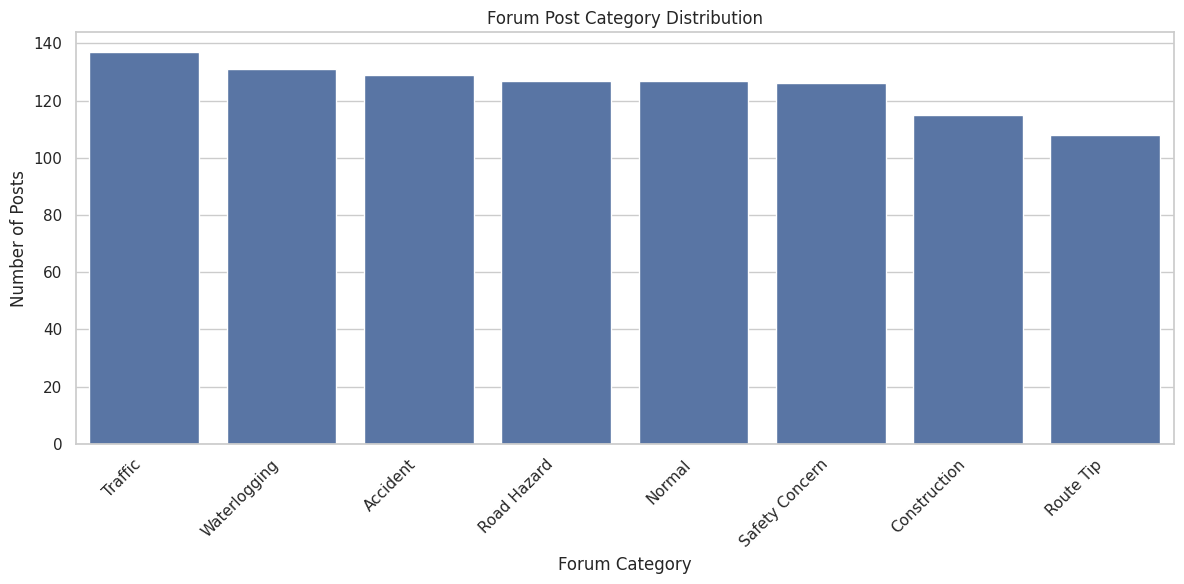

,Post_Count
category,
Traffic,137
Waterlogging,131
Accident,129
Road Hazard,127
Normal,127
Safety Concern,126
Construction,115
Route Tip,108


In [ ]:
category_counts = posts["category"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Forum Post Category Distribution")
plt.xlabel("Forum Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

display(category_counts.to_frame("Post_Count"))

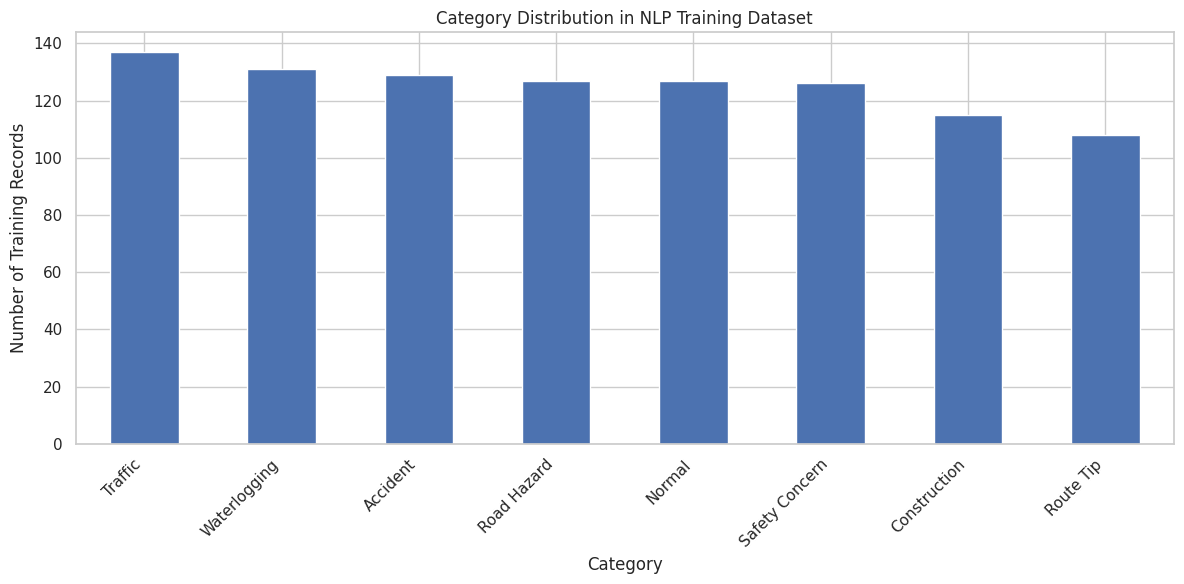

In [ ]:
plt.figure(figsize=(12, 6))

training["category"].value_counts().plot(
    kind="bar"
)

plt.title("Category Distribution in NLP Training Dataset")
plt.xlabel("Category")
plt.ylabel("Number of Training Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Severity values:
severity
Low       384
Medium    347
High      269
Name: count, dtype: int64


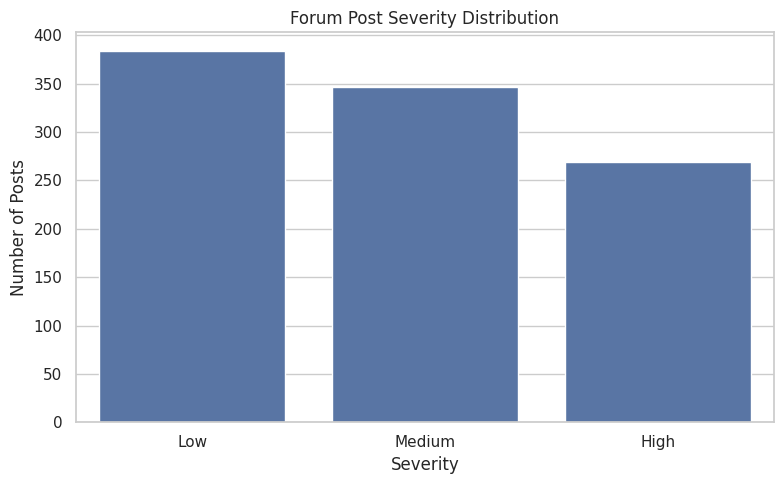

In [ ]:
print("Severity values:")
print(posts["severity"].value_counts(dropna=False))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=posts,
    x="severity",
    order=posts["severity"].value_counts().index
)

plt.title("Forum Post Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

Sentiment values:
sentiment
Negative    650
Positive    235
Neutral     115
Name: count, dtype: int64


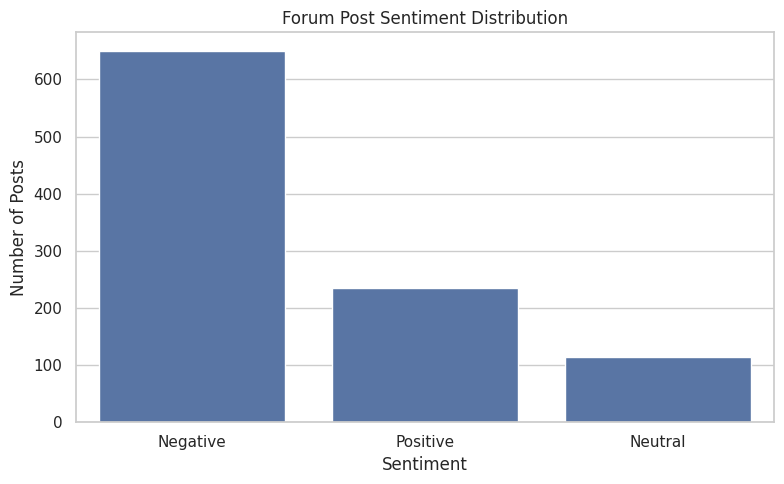

In [ ]:
print("Sentiment values:")
print(posts["sentiment"].value_counts(dropna=False))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=posts,
    x="sentiment",
    order=posts["sentiment"].value_counts().index
)

plt.title("Forum Post Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

severity,High,Low,Medium
category,,,
Accident,78,0,51
Construction,0,75,40
Normal,0,127,0
Road Hazard,69,0,58
Route Tip,0,108,0
Safety Concern,22,48,56
Traffic,36,26,75
Waterlogging,64,0,67


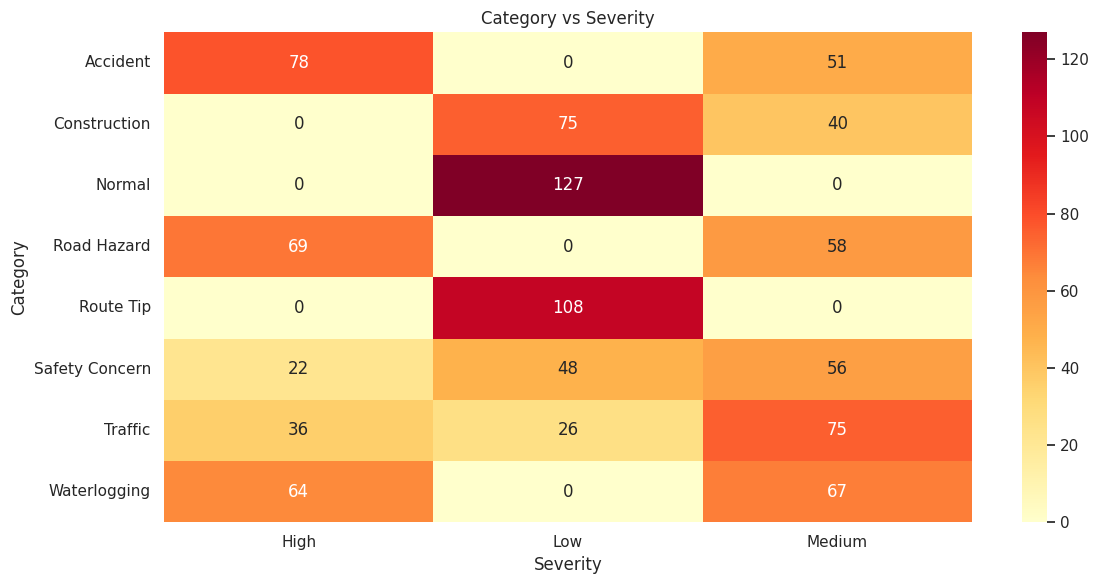

In [ ]:
severity_table = pd.crosstab(
    posts["category"],
    posts["severity"]
)

display(severity_table)

plt.figure(figsize=(12, 6))

sns.heatmap(
    severity_table,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Category vs Severity")
plt.xlabel("Severity")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [ ]:
posts["latitude"] = pd.to_numeric(
    posts["latitude"],
    errors="coerce"
)

posts["longitude"] = pd.to_numeric(
    posts["longitude"],
    errors="coerce"
)

invalid_coordinates = posts[
    posts["latitude"].isna() |
    posts["longitude"].isna() |
    ~posts["latitude"].between(-90, 90) |
    ~posts["longitude"].between(-180, 180)
]

print("Total posts:", len(posts))
print("Invalid coordinates:", len(invalid_coordinates))

display(
    invalid_coordinates[
        ["post_id", "latitude", "longitude"]
    ].head(10)
)

Total posts: 1000
Invalid coordinates: 0


,post_id,latitude,longitude


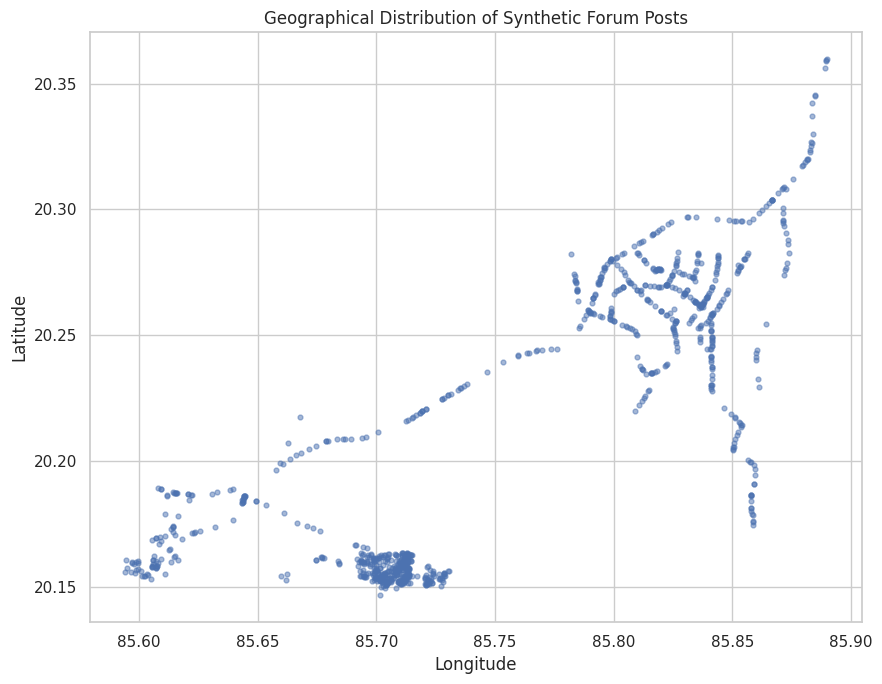

In [ ]:
valid_coordinates = posts.dropna(
    subset=["latitude", "longitude"]
)

valid_coordinates = valid_coordinates[
    valid_coordinates["latitude"].between(-90, 90) &
    valid_coordinates["longitude"].between(-180, 180)
]

plt.figure(figsize=(9, 7))

plt.scatter(
    valid_coordinates["longitude"],
    valid_coordinates["latitude"],
    alpha=0.5,
    s=12
)

plt.title("Geographical Distribution of Synthetic Forum Posts")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

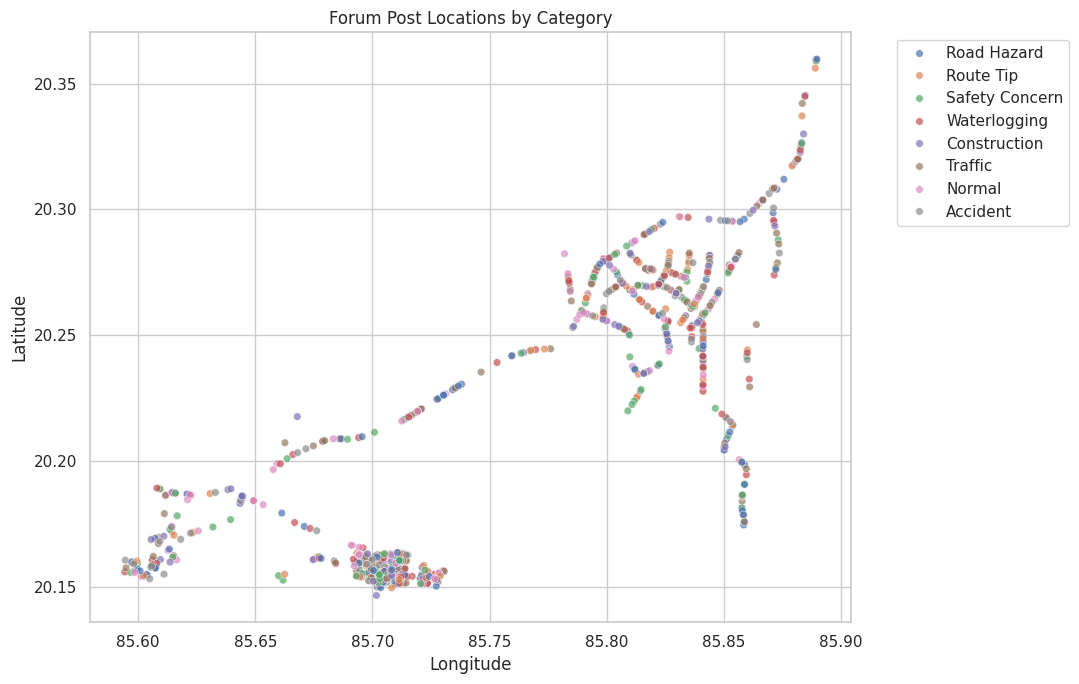

In [ ]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=valid_coordinates,
    x="longitude",
    y="latitude",
    hue="category",
    alpha=0.7,
    s=30
)

plt.title("Forum Post Locations by Category")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
date_columns = [
    "created_at",
    "observed_at",
    "expires_at"
]

for col in date_columns:

    if col in posts.columns:

        posts[col] = pd.to_datetime(
            posts[col],
            errors="coerce",
            utc=True
        )

print(posts[date_columns].dtypes)

created_at     datetime64[ns, UTC]
observed_at    datetime64[ns, UTC]
expires_at     datetime64[ns, UTC]
dtype: object


In [ ]:
for col in date_columns:

    if col in posts.columns:

        print(
            col,
            "Invalid or missing:",
            posts[col].isna().sum()
        )

created_at Invalid or missing: 0
observed_at Invalid or missing: 0
expires_at Invalid or missing: 0


In [ ]:
if "expires_at" in posts.columns:

    if "created_at" in posts.columns:

        invalid_expiry = posts[
            posts["expires_at"] < posts["created_at"]
        ]

        print(
            "Posts expiring before creation:",
            len(invalid_expiry)
        )

        display(
            invalid_expiry[
                ["post_id", "created_at", "expires_at"]
            ].head()
        )

Posts expiring before creation: 0


,post_id,created_at,expires_at


In [ ]:
if "status" in posts.columns:

    print("Post status distribution:")
    print(posts["status"].value_counts(dropna=False))

if "verification_status" in posts.columns:

    print("\nVerification status distribution:")
    print(
        posts["verification_status"].value_counts(
            dropna=False
        )
    )

Post status distribution:
status
Expired    792
Active     208
Name: count, dtype: int64

Verification status distribution:
verification_status
synthetic_unverified    1000
Name: count, dtype: int64


In [ ]:
valid_post_ids = set(posts["post_id"])

orphan_comments = comments[
    ~comments["post_id"].isin(valid_post_ids)
]

print("Total comments:", len(comments))
print("Orphan comments:", len(orphan_comments))

Total comments: 1949
Orphan comments: 0


In [ ]:
comment_counts = (
    comments.groupby("post_id")
    .size()
    .reset_index(name="actual_comment_count")
)

post_comment_summary = posts[
    ["post_id", "category"]
].merge(
    comment_counts,
    on="post_id",
    how="left"
)

post_comment_summary["actual_comment_count"] = (
    post_comment_summary["actual_comment_count"]
    .fillna(0)
    .astype(int)
)

display(post_comment_summary.head(10))

,post_id,category,actual_comment_count
0,P00001,Road Hazard,1
1,P00002,Route Tip,1
2,P00003,Route Tip,3
3,P00004,Safety Concern,3
4,P00005,Safety Concern,2
5,P00006,Waterlogging,3
6,P00007,Road Hazard,1
7,P00008,Waterlogging,1
8,P00009,Construction,1
9,P00010,Safety Concern,1


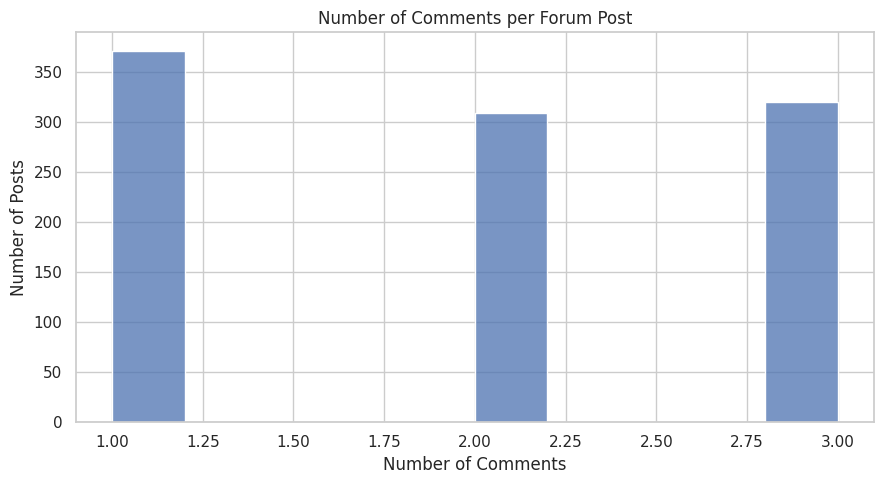

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    post_comment_summary["actual_comment_count"],
    bins=10,
    kde=False
)

plt.title("Number of Comments per Forum Post")
plt.xlabel("Number of Comments")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

In [ ]:
if "comment_count" in posts.columns:

    comparison = posts[
        ["post_id", "comment_count"]
    ].merge(
        comment_counts,
        on="post_id",
        how="left"
    )

    comparison["actual_comment_count"] = (
        comparison["actual_comment_count"]
        .fillna(0)
    )

    comparison["comment_count"] = pd.to_numeric(
        comparison["comment_count"],
        errors="coerce"
    )

    comparison["count_matches"] = (
        comparison["comment_count"] ==
        comparison["actual_comment_count"]
    )

    print(
        "Matching comment counts:",
        comparison["count_matches"].sum()
    )

    print(
        "Mismatched comment counts:",
        (~comparison["count_matches"]).sum()
    )

    display(comparison.head(10))

Matching comment counts: 1000
Mismatched comment counts: 0


,post_id,comment_count,actual_comment_count,count_matches
0,P00001,1,1,True
1,P00002,1,1,True
2,P00003,3,3,True
3,P00004,3,3,True
4,P00005,2,2,True
5,P00006,3,3,True
6,P00007,1,1,True
7,P00008,1,1,True
8,P00009,1,1,True
9,P00010,1,1,True


In [ ]:
posts["text_length"] = (
    posts["text"].fillna("").astype(str).str.len()
)

training["text_length"] = (
    training["combined_text"]
    .fillna("")
    .astype(str)
    .str.len()
)

print("Forum Post Text Length:")
display(posts["text_length"].describe())

print("\nTraining Text Length:")
display(training["text_length"].describe())

Forum Post Text Length:


,text_length
count,1000.000000
mean,78.744000
std,7.709468
min,64.000000
25%,73.000000
50%,80.000000
75%,84.250000
max,96.000000



Training Text Length:


,text_length
count,1000.000000
mean,106.491000
std,10.280545
min,87.000000
25%,100.750000
50%,105.000000
75%,112.000000
max,134.000000


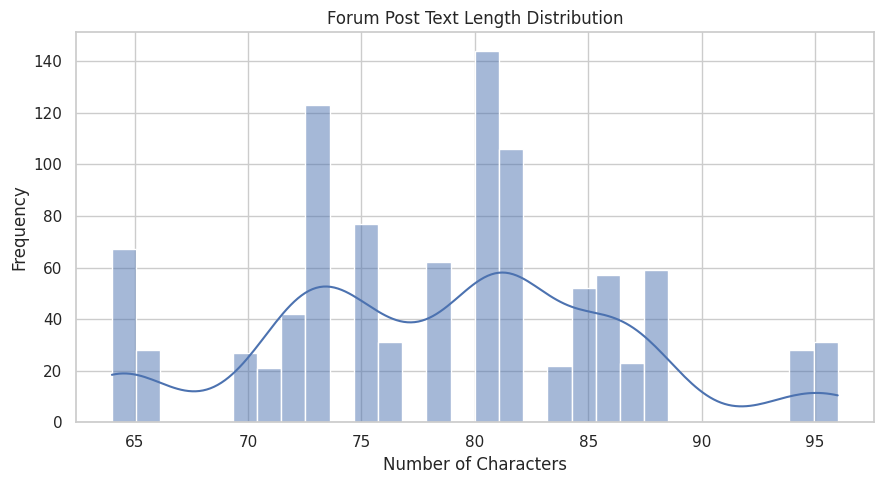

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    posts["text_length"],
    bins=30,
    kde=True
)

plt.title("Forum Post Text Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
for category in expected_categories:

    category_data = posts[
        posts["category"] == category
    ]

    print("\n" + "=" * 60)
    print("CATEGORY:", category)
    print("=" * 60)

    if not category_data.empty:

        display(
            category_data[
                ["title", "text", "severity", "sentiment"]
            ].head(3)
        )


CATEGORY: Traffic


,title,text,severity,sentiment
11,Heavy traffic near Bhubaneswar road segment,Vehicles are moving very slowly near Bhubanesw...,High,Negative
15,Congestion during evening hours,Traffic density appears high near Bhubaneswar ...,Low,Negative
20,Traffic congestion reported,A long queue of vehicles has formed near Bhuba...,High,Negative



CATEGORY: Accident


,title,text,severity,sentiment
14,Vehicle collision reported,A vehicle collision is reported in the vicinit...,High,Negative
17,Road incident reported,A road incident has been reported near Bhubane...,High,Negative
28,Minor accident near road junction,A simulated minor accident report is associate...,Medium,Negative



CATEGORY: Road Hazard


,title,text,severity,sentiment
0,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Medium,Negative
6,Uneven road conditions,Drivers may experience difficulty due to uneve...,High,Negative
25,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,High,Negative


... (4 outputs left out)


CATEGORY: Safety Concern


,title,text,severity,sentiment
3,Unsafe road conditions,The road section near Bhubaneswar road segment...,Medium,Negative
4,Unsafe road conditions,The road section near Bhubaneswar road segment...,Medium,Negative
9,Poor visibility at night,Visibility may be reduced near Bhubaneswar roa...,High,Negative



CATEGORY: Road Quality

CATEGORY: Route Suggestions

CATEGORY: Travel Tips

CATEGORY: General Experience

CATEGORY: Normal


,title,text,severity,sentiment
12,Clear road conditions,No traffic-related issue is mentioned for the ...,Low,Positive
21,Smooth traffic movement,Vehicles are reportedly moving smoothly near B...,Low,Positive
22,Normal travel conditions,Travel conditions are described as normal near...,Low,Positive


In [ ]:
duplicate_texts = training[
    training["combined_text"].duplicated(keep=False)
].sort_values("combined_text")

print("Repeated training text records:", len(duplicate_texts))

display(duplicate_texts.head(20))

Repeated training text records: 1000


,post_id,title,text,category,severity,template_id,is_synthetic,combined_text,text_length
174,P00175,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,High,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
121,P00122,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,Medium,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
307,P00308,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,Medium,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
542,P00543,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,High,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
660,P00661,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,Medium,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
659,P00660,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,Medium,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
898,P00899,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,High,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
553,P00554,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,Medium,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
915,P00916,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,High,Accident_03,True,Accident-related traffic delay Traffic movemen...,116
344,P00345,Accident-related traffic delay,Traffic movement may be affected by an acciden...,Accident,Medium,Accident_03,True,Accident-related traffic delay Traffic movemen...,116


In [ ]:
for name, df in datasets.items():

    print("\n", name)

    if "is_synthetic" in df.columns:

        print(
            df["is_synthetic"].value_counts(
                dropna=False
            )
        )

    else:

        print("is_synthetic column not found!")


 Forum Posts
is_synthetic
True    1000
Name: count, dtype: int64

 Forum Comments
is_synthetic
True    1949
Name: count, dtype: int64

 Forum Training
is_synthetic
True    1000
Name: count, dtype: int64


In [ ]:
posts_clean = posts.copy()
comments_clean = comments.copy()
training_clean = training.copy()

# Remove accidental whitespace from text fields
for col in ["title", "text", "category", "severity", "sentiment"]:
    if col in posts_clean.columns:
        posts_clean[col] = posts_clean[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

for col in ["comment_text"]:
    if col in comments_clean.columns:
        comments_clean[col] = comments_clean[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

for col in ["combined_text", "category"]:
    if col in training_clean.columns:
        training_clean[col] = training_clean[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

print("Clean copies created!")

Clean copies created!


In [ ]:
posts_before = len(posts_clean)
comments_before = len(comments_clean)
training_before = len(training_clean)

posts_clean = posts_clean.drop_duplicates(
    subset=["post_id"],
    keep="first"
)

comments_clean = comments_clean.drop_duplicates(
    subset=["comment_id"],
    keep="first"
)

training_clean = training_clean.drop_duplicates(
    subset=["post_id"],
    keep="first"
)

print("Duplicate post IDs removed:", posts_before - len(posts_clean))
print("Duplicate comment IDs removed:", comments_before - len(comments_clean))
print("Duplicate training post IDs removed:", training_before - len(training_clean))

Duplicate post IDs removed: 0
Duplicate comment IDs removed: 0
Duplicate training post IDs removed: 0


In [ ]:
posts_clean = posts_clean.dropna(
    subset=["post_id", "title", "text", "category"]
)

comments_clean = comments_clean.dropna(
    subset=["comment_id", "post_id", "comment_text"]
)

training_clean = training_clean.dropna(
    subset=["post_id", "combined_text", "category"]
)

# Remove blank text records
posts_clean = posts_clean[
    posts_clean["title"].astype(str).str.strip().ne("") &
    posts_clean["text"].astype(str).str.strip().ne("")
]

comments_clean = comments_clean[
    comments_clean["comment_text"].astype(str).str.strip().ne("")
]

training_clean = training_clean[
    training_clean["combined_text"].astype(str).str.strip().ne("")
]

print("Posts remaining:", len(posts_clean))
print("Comments remaining:", len(comments_clean))
print("Training records remaining:", len(training_clean))

Posts remaining: 1000
Comments remaining: 1949
Training records remaining: 1000


In [ ]:
valid_post_ids = set(posts_clean["post_id"])

comments_before = len(comments_clean)

comments_clean = comments_clean[
    comments_clean["post_id"].isin(valid_post_ids)
].copy()

print(
    "Invalid comments removed:",
    comments_before - len(comments_clean)
)

Invalid comments removed: 0


In [ ]:
post_category_mapping = (
    posts_clean.set_index("post_id")["category"].to_dict()
)

training_before = len(training_clean)

training_clean["post_category"] = (
    training_clean["post_id"].map(post_category_mapping)
)

# Keep only records with a matching post and category
training_clean = training_clean[
    training_clean["post_category"].notna() &
    (
        training_clean["category"] ==
        training_clean["post_category"]
    )
].copy()

training_clean.drop(
    columns=["post_category"],
    inplace=True
)

print(
    "Invalid training records removed:",
    training_before - len(training_clean)
)

print("Validated training records:", len(training_clean))

Invalid training records removed: 0
Validated training records: 1000


In [ ]:
quality_report = pd.DataFrame([
    {
        "Dataset": "Forum Posts",
        "Original_Records": len(posts),
        "Validated_Records": len(posts_clean),
        "Removed_Records": len(posts) - len(posts_clean)
    },
    {
        "Dataset": "Forum Comments",
        "Original_Records": len(comments),
        "Validated_Records": len(comments_clean),
        "Removed_Records": len(comments) - len(comments_clean)
    },
    {
        "Dataset": "Forum Training",
        "Original_Records": len(training),
        "Validated_Records": len(training_clean),
        "Removed_Records": len(training) - len(training_clean)
    }
])

display(quality_report)

,Dataset,Original_Records,Validated_Records,Removed_Records
0,Forum Posts,1000,1000,0
1,Forum Comments,1949,1949,0
2,Forum Training,1000,1000,0


In [ ]:
print("FINAL VALIDATION RESULTS")
print("=" * 50)

print("\nPosts:")
print("Records:", len(posts_clean))
print("Duplicate IDs:", posts_clean["post_id"].duplicated().sum())
print("Missing essential values:",
      posts_clean[["post_id", "title", "text", "category"]].isnull().sum().sum())

print("\nComments:")
print("Records:", len(comments_clean))
print("Duplicate IDs:", comments_clean["comment_id"].duplicated().sum())
print("Orphan comments:",
      (~comments_clean["post_id"].isin(posts_clean["post_id"])).sum())

print("\nTraining:")
print("Records:", len(training_clean))
print("Duplicate post IDs:", training_clean["post_id"].duplicated().sum())
print("Missing essential values:",
      training_clean[["post_id", "combined_text", "category"]].isnull().sum().sum())

print("\nAll final checks completed!")

FINAL VALIDATION RESULTS

Posts:
Records: 1000
Duplicate IDs: 0
Missing essential values: 0

Comments:
Records: 1949
Duplicate IDs: 0
Orphan comments: 0

Training:
Records: 1000
Duplicate post IDs: 0
Missing essential values: 0

All final checks completed!


In [ ]:
posts_clean.to_csv(
    os.path.join(VALIDATED_PATH, "forum_posts_validated.csv"),
    index=False
)

comments_clean.to_csv(
    os.path.join(VALIDATED_PATH, "forum_comments_validated.csv"),
    index=False
)

training_clean.to_csv(
    os.path.join(VALIDATED_PATH, "forum_training_validated.csv"),
    index=False
)

print("Validated datasets saved successfully!")

Validated datasets saved successfully!


In [ ]:
quality_report.to_csv(
    os.path.join(REPORT_PATH, "forum_data_quality_report.csv"),
    index=False
)

combined_missing_report.to_csv(
    os.path.join(REPORT_PATH, "forum_missing_values_report.csv"),
    index=False
)

category_counts.to_csv(
    os.path.join(REPORT_PATH, "forum_category_distribution.csv")
)

severity_table.to_csv(
    os.path.join(REPORT_PATH, "forum_category_severity.csv")
)

post_comment_summary.to_csv(
    os.path.join(REPORT_PATH, "post_comment_summary.csv"),
    index=False
)

print("All validation reports saved!")
print("Location:", REPORT_PATH)

All validation reports saved!
Location: /content/drive/MyDrive/Smart_Ride_Intelligence/reports/forum_validation
